# Modelling ML — Random Forest (Disetarakan dengan Tabular Conformer)

Notebook ini merupakan versi baseline Random Forest yang protokol eksperimennya disamakan dengan notebook utama **Tabular Conformer**.

Penyesuaian utama:
- Menggunakan `merge_DocLab_balanced.csv` sebagai dataset Plan B.
- Menggunakan **13 fitur dan urutan fitur yang sama** dengan Conformer.
- Menggunakan pembagian data stratified **70% train, 15% validation, 15% test** dengan `random_state=42`.
- Tidak melakukan seleksi fitur pada seluruh dataset sebelum splitting.
- Memilih konfigurasi Random Forest berdasarkan macro-F1 validation; test dipakai untuk evaluasi final.

> Catatan metodologi: notebook ini menyamakan protokol perbandingan model. Ia tidak menghapus keterbatasan bahwa balancing pada dataset sumber telah dilakukan sebelum splitting.

## 1. Import Library

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42

FEATURES = [
    'JENIS_KELAMIN',
    'UMUR_TAHUN',
    'cholesterol total',
    'creatinin',
    'fbs',
    'rbs',
    'hgb',
    'lymfosit%',
    'mch',
    'mchc',
    'mcv',
    'ureum',
    'wbc',
]

CLASS_NAMES = [
    'Sehat / Tidak Ada Indikasi',
    'Jantung dan Pembuluh Darah',
    'Spes. Penyakit Dalam',
    'Spes. Paru-Paru',
]

## 2. Load Dataset

In [ ]:
# Pastikan file CSV berada di folder kerja notebook.
df = pd.read_csv('merge_DocLab_balanced.csv')

print('Shape dataset:', df.shape)
df.head()

Shape dataset: (7100, 14)


,JENIS_KELAMIN,UMUR_TAHUN,cholesterol total,creatinin,fbs,rbs,hgb,lymfosit%,mch,mchc,mcv,ureum,wbc,NM_UNIT
0,1,61.0,169.98,0.40,115.3,220.4,11.0,14.4,25.8,32.4,79.6,100.0,9.9,0
1,0,59.0,111.00,1.68,70.0,193.4,12.0,26.9,25.9,34.0,76.2,100.0,14.7,0
2,1,40.0,166.59,0.78,117.2,70.0,13.1,12.6,28.7,32.8,88.1,46.0,11.9,0
3,1,69.0,218.78,2.50,103.7,161.8,9.4,30.3,20.8,29.7,69.8,10.0,5.8,0
4,1,45.0,222.84,1.22,79.3,217.3,8.2,20.5,26.6,37.0,105.0,100.0,15.9,0


## 3. Validasi Fitur dan Target

In [ ]:
# Pastikan nama kolom sama dengan yang digunakan pada notebook Conformer.
required_cols = FEATURES + ['NM_UNIT']
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise KeyError(
        f'Kolom tidak ditemukan: {missing_cols}. Periksa nama kolom pada CSV dan samakan dengan notebook Conformer.'
    )

df_model = df[required_cols].copy()
df_model['NM_UNIT'] = pd.to_numeric(df_model['NM_UNIT'], errors='raise').astype(int)
df_model[FEATURES] = df_model[FEATURES].apply(pd.to_numeric, errors='coerce')

missing_summary = df_model[FEATURES + ['NM_UNIT']].isna().sum()
print('Jumlah missing value per kolom:')
missing_summary[missing_summary > 0]

if df_model[FEATURES].isna().any().any():
    raise ValueError('Masih ada missing/non-numeric pada fitur. Selesaikan dengan prosedur preprocessing yang sama sebelum modeling.')

valid_classes = sorted(df_model['NM_UNIT'].unique().tolist())
print('Kelas yang ditemukan:', valid_classes)
if valid_classes != [0, 1, 2, 3]:
    raise ValueError(f'Target seharusnya berisi kelas [0, 1, 2, 3], tetapi ditemukan {valid_classes}.')

print('Distribusi kelas:')
df_model['NM_UNIT'].value_counts().sort_index().rename(index=dict(enumerate(CLASS_NAMES))).to_frame('Jumlah')

Jumlah missing value per kolom:
Kelas yang ditemukan: [0, 1, 2, 3]
Distribusi kelas:


,Jumlah
NM_UNIT,
Sehat / Tidak Ada Indikasi,2100
Jantung dan Pembuluh Darah,1500
Spes. Penyakit Dalam,2000
Spes. Paru-Paru,1500


## 4. Tentukan X dan y

In [ ]:
X = df_model[FEATURES].copy()
y = df_model['NM_UNIT'].copy()

print('X:', X.shape)
print('y:', y.shape)

X: (7100, 13)
y: (7100,)


## 5. Split Data (Sama dengan Conformer)

In [ ]:
# 70% train, 15% validation, 15% test.
# Urutan split dan random_state dibuat sama dengan notebook Tabular Conformer.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED,
)

print('Train      :', X_train.shape, y_train.shape)
print('Validation :', X_val.shape, y_val.shape)
print('Test       :', X_test.shape, y_test.shape)

Train      : (4970, 13) (4970,)
Validation : (1065, 13) (1065,)
Test       : (1065, 13) (1065,)


## 6. Training dan Pemilihan Konfigurasi

In [ ]:
# RF tidak membutuhkan StandardScaler. Konfigurasi dipilih menggunakan macro-F1 validation.
# Test set tidak digunakan saat memilih konfigurasi.
rf_configs = [
    {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'},
    {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 'sqrt'},
    {'n_estimators': 300, 'max_depth': 20,   'min_samples_leaf': 1, 'max_features': 'sqrt'},
]

validation_results = []
best_model = None
best_config = None
best_val_f1 = -1.0

for i, config in enumerate(rf_configs, start=1):
    model = RandomForestClassifier(
        **config,
        random_state=SEED,
        class_weight=None,
        n_jobs=-1,
    )
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)
    val_macro_f1 = f1_score(y_val, val_pred, average='macro', zero_division=0)

    validation_results.append({
        'Percobaan': i,
        **config,
        'Validation Macro-F1': val_macro_f1,
    })

    print(f'Percobaan {i}/{len(rf_configs)} | validation macro-F1 = {val_macro_f1:.4f} | config = {config}')

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        best_model = model
        best_config = config.copy()

validation_results = pd.DataFrame(validation_results).sort_values(
    'Validation Macro-F1', ascending=False
).reset_index(drop=True)

print('Konfigurasi terbaik:', best_config)
print(f'Best validation macro-F1: {best_val_f1:.4f}')
validation_results

Percobaan 1/3 | validation macro-F1 = 0.8833 | config = {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Percobaan 2/3 | validation macro-F1 = 0.8780 | config = {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
Percobaan 3/3 | validation macro-F1 = 0.8859 | config = {'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Konfigurasi terbaik: {'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Best validation macro-F1: 0.8859


,Percobaan,n_estimators,max_depth,min_samples_leaf,max_features,Validation Macro-F1
0,3,300,20.0,1,sqrt,0.885900
1,1,200,NaN,1,sqrt,0.883261
2,2,300,NaN,2,sqrt,0.877989


## 7. Evaluasi Final pada Test Set

In [ ]:
def evaluate_model(model, X_eval, y_eval, split_name='Test'):
    y_pred_eval = model.predict(X_eval)
    metrics = {
        'Split': split_name,
        'Accuracy': accuracy_score(y_eval, y_pred_eval),
        'Macro Precision': precision_score(y_eval, y_pred_eval, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_eval, y_pred_eval, average='macro', zero_division=0),
        'Macro F1': f1_score(y_eval, y_pred_eval, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_eval, y_pred_eval),
    }
    print(f'=== {split_name} ===')
    print(classification_report(y_eval, y_pred_eval, labels=[0, 1, 2, 3], target_names=CLASS_NAMES, zero_division=0))
    return metrics, y_pred_eval

val_metrics, y_val_pred = evaluate_model(best_model, X_val, y_val, 'Validation')
test_metrics, y_pred = evaluate_model(best_model, X_test, y_test, 'Test')

pd.DataFrame([val_metrics, test_metrics]).set_index('Split').round(4)

=== Validation ===
                            precision    recall  f1-score   support

Sehat / Tidak Ada Indikasi       0.89      0.87      0.88       315
Jantung dan Pembuluh Darah       0.86      0.87      0.87       225
      Spes. Penyakit Dalam       0.91      0.86      0.89       300
           Spes. Paru-Paru       0.87      0.96      0.92       225

                  accuracy                           0.89      1065
                 macro avg       0.88      0.89      0.89      1065
              weighted avg       0.89      0.89      0.89      1065

=== Test ===
                            precision    recall  f1-score   support

Sehat / Tidak Ada Indikasi       0.88      0.90      0.89       315
Jantung dan Pembuluh Darah       0.89      0.84      0.86       225
      Spes. Penyakit Dalam       0.93      0.89      0.91       300
           Spes. Paru-Paru       0.90      0.97      0.94       225

                  accuracy                           0.90      1065
           

,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
Split,,,,,
Validation,0.8854,0.8839,0.8894,0.8859,0.8894
Test,0.9005,0.9001,0.9010,0.8999,0.9010


### Confusion Matrix — Random Forest

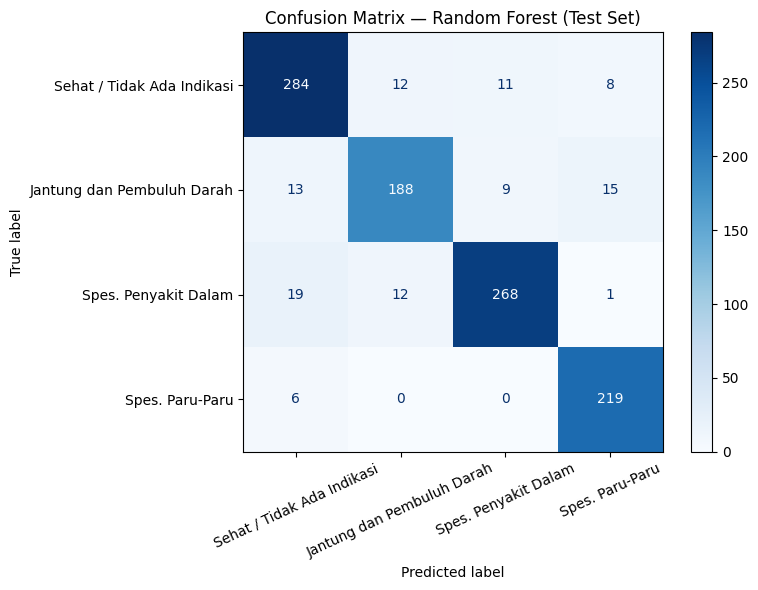

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    display_labels=CLASS_NAMES,
    cmap='Blues',
    xticks_rotation=25,
    ax=ax,
)
plt.title('Confusion Matrix — Random Forest (Test Set)')
plt.tight_layout()
plt.show()

### Feature Importance

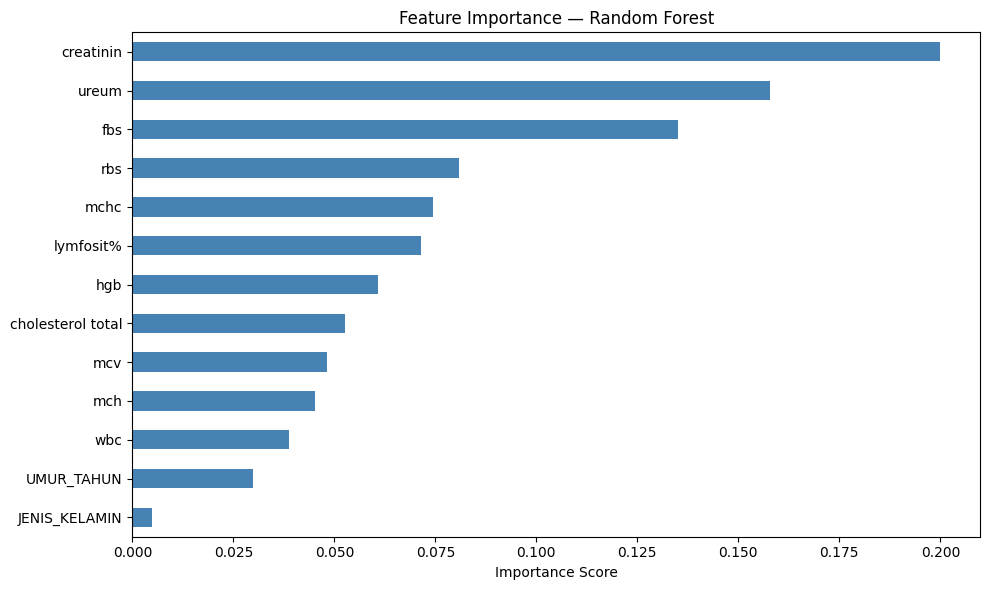

,Importance
creatinin,0.199820
ureum,0.157712
fbs,0.135160
rbs,0.080890
mchc,0.074434
lymfosit%,0.071456
hgb,0.060923
cholesterol total,0.052628
mcv,0.048112
mch,0.045228


In [ ]:
fi = pd.Series(best_model.feature_importances_, index=FEATURES).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
fi.sort_values().plot(kind='barh', color='steelblue')
plt.title('Feature Importance — Random Forest')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

fi.rename('Importance').to_frame()

## 8. Simpan Hasil Metrik

In [ ]:
rf_test_summary = {
    'Model': 'Random Forest',
    'Accuracy': test_metrics['Accuracy'],
    'Macro Precision': test_metrics['Macro Precision'],
    'Macro Recall': test_metrics['Macro Recall'],
    'Macro F1': test_metrics['Macro F1'],
    'Balanced Accuracy': test_metrics['Balanced Accuracy'],
    'Best Config': str(best_config),
}

rf_test_summary_df = pd.DataFrame([rf_test_summary])
rf_test_summary_df.to_csv('random_forest_test_metrics.csv', index=False)
print('Metrik disimpan ke random_forest_test_metrics.csv')
rf_test_summary_df.round(4)

Metrik disimpan ke random_forest_test_metrics.csv


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy,Best Config
0,Random Forest,0.9005,0.9001,0.901,0.8999,0.901,"{'n_estimators': 300, 'max_depth': 20, 'min_sa..."


## Catatan untuk Bab III/Bab IV

- Random Forest dan Conformer menggunakan fitur, seed, serta indeks train/validation/test yang sama.
- Random Forest dipilih berdasarkan macro-F1 validation; metrik test dilaporkan setelah konfigurasi dipilih.
- Random Forest tidak memerlukan scaling, sedangkan Conformer menggunakan `StandardScaler` yang di-fit pada train saja. Ini merupakan perbedaan preprocessing yang wajar berdasarkan kebutuhan algoritma.
- Dataset ini adalah dataset hasil balancing yang digunakan sebagai Plan B. Karena balancing sumber dilakukan sebelum splitting, keterbatasan ini perlu disebutkan saat menginterpretasikan generalisasi hasil.